<div dir="rtl">

# 01 · EDA: תאונות דרכים עם נפגעים 2024

**הדאטה:** קובץ פרטני של הלמ"ס, `h20241331data.csv` מ־data.gov.il. כל שורה היא תאונה אחת.
**המטרה:** לחזות את `HUMRAT_TEUNA` (חומרת התאונה): 1 = קטלנית, 2 = קשה, 3 = קלה.

> כל תא קוד במחברת נכתב בעזרת Claude, ולכן מסומן `### CODE BY CLAUDE ###` לפי הנחיות המרצה.
> הפירוש של הקודים לקוח ממילון הקודים של הלמ"ס (`data/raw/codes_dictionary_subset.csv`).

</div>

In [1]:
### CODE BY CLAUDE ###
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # כדי שאפשר יהיה לייבא את src

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import (load_raw, add_features, get_xy, build_preprocessor, FIGURES,
                      RANDOM_STATE, TARGET, SEVERITY_NAMES, CATEGORICAL, NUMERIC, BINARY,
                      label, COLUMN_NAMES)

sns.set_theme(style="whitegrid")
FIGURES.mkdir(exist_ok=True)
SEV_ORDER = ["קטלנית", "קשה", "קלה"]
SEV_COLORS = ["#a3262c", "#e08a2c", "#7a8aa0"]
####

<div dir="rtl">

**מאיזה שיעור כל דבר:** טיפול בדאטה לא מאוזן, `stratify`, Data Leakage, Macro F1 (שיעור 1) · Scaling ו־One-hot (שיעור 2) · כפילויות, השלמת חסרים, נרמול ו־PCA (שיעור 3).
שאר המחברת היא תיאור הדאטה בטבלאות ובגרפים פשוטים (אחוזים וספירות).

</div>

<div dir="rtl">

## 1. גודל הדאטה ובדיקת הדרישות
המרצה דורש יותר מ־140 שורות ולפחות 15 פיצ'רים משמעותיים.

</div>

In [2]:
### CODE BY CLAUDE ###
df = load_raw()
print("שורות, עמודות:", df.shape)
df.head()
####

שורות, עמודות: (8315, 45)


,pk_teuna_fikt,sug_tik,THUM_GEOGRAFI,SUG_DEREH,SEMEL_YISHUV,REHOV1,REHOV2,BAYIT,ZOMET_IRONI,KVISH1,...,MEKOM_HAZIYA,KIVUN_HAZIYA,MAHOZ,NAFA,EZOR_TIVI,MAAMAD_MINIZIPALI,ZURAT_ISHUV,STATUS_IGUN,X,Y
0,2023096257,1,1,1,8600,1505.0,1619.0,NaN,160223.0,NaN,...,3,9,5,51,512,0.0,14,1,184053.0,663193.0
1,2024000009,1,1,2,3000,5403.0,NaN,41.0,NaN,NaN,...,0,9,1,11,111,0.0,12,1,221817.0,628497.0
2,2024000034,1,1,2,7900,148.0,NaN,2.0,NaN,NaN,...,0,9,4,42,422,0.0,13,3,190310.0,668268.0
3,2024000069,1,1,4,0,NaN,NaN,NaN,NaN,2411.0,...,0,9,6,62,622,99.0,99,3,168970.0,580206.0
4,2024000076,1,1,4,0,NaN,NaN,NaN,NaN,2.0,...,0,9,4,41,411,99.0,99,1,188598.0,695708.0


In [3]:
### CODE BY CLAUDE ###
# כמה ערכים שונים יש בכל עמודה, וכמה חסר
profile = pd.DataFrame({
    "ערכים שונים": df.nunique(),
    "% חסר": (df.isna().mean() * 100).round(1),
}).sort_values("ערכים שונים")
profile
####

,ערכים שונים,% חסר
sug_tik,1,0.0
SHNAT_TEUNA,1,0.0
THUM_GEOGRAFI,2,0.0
YOM_LAYLA,2,0.0
HUMRAT_TEUNA,3,0.0
KIVUN_HAZIYA,3,0.0
SUG_DEREH,4,0.0
SUG_YOM,4,0.0
TKINUT,5,0.0
SIMUN_TIMRUR,5,0.0


<div dir="rtl">

**מה רואים:**
- `sug_tik` ו־`SHNAT_TEUNA` עם ערך אחד בלבד, ו־`pk_teuna_fikt` הוא מזהה (ערך שונה בכל שורה). לא נושאים מידע, ולכן נזרקים.
- עמודות כמו רחוב, צומת, כביש וק"מ הן **מזהים** עם מאות ערכים שונים. One-hot שלהן היה יוצר אלפי עמודות, ולכן מחליפים אותן בדגלים פשוטים ובמיקום גס יותר (מחוז, נפה, X, Y).

</div>

<div dir="rtl">

## 2. משתנה המטרה: הדאטה לא מאוזן (שיעור 1)

</div>

              מספר תאונות     %
HUMRAT_TEUNA                   
קטלנית                405   4.9
קשה                  2452  29.5
קלה                  5458  65.6


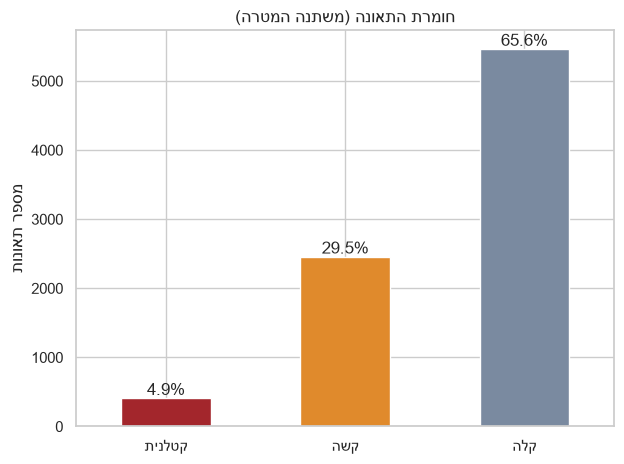

In [4]:
### CODE BY CLAUDE ###
counts = df[TARGET].map(SEVERITY_NAMES).value_counts().reindex(SEV_ORDER)
pct = (counts / counts.sum() * 100).round(1)
print(pd.DataFrame({"מספר תאונות": counts, "%": pct}))

ax = counts.plot.bar(color=SEV_COLORS, rot=0)
for p, v in zip(ax.patches, pct):
    ax.annotate(f"{v}%", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("חומרת התאונה (משתנה המטרה)")
ax.set_xlabel("")
ax.set_ylabel("מספר תאונות")
plt.tight_layout(); plt.savefig(FIGURES / "01_target_distribution.png", dpi=150); plt.show()
####

<div dir="rtl">

**מסקנה:** רק כ־4.9% מהתאונות קטלניות. מודל שעונה תמיד "קלה" יקבל Accuracy של 66% בלי ללמוד כלום.
לכן בהמשך: `stratify` בפיצול, מדדים כמו F1-macro ו־Recall של "קטלנית", והשוואה של שיטות איזון (class_weight, SMOTE).

</div>

<div dir="rtl">

## 3. ערכים חסרים: חוסר מבני
השאלה: האם החוסר אקראי, או שיש לו סיבה?

</div>

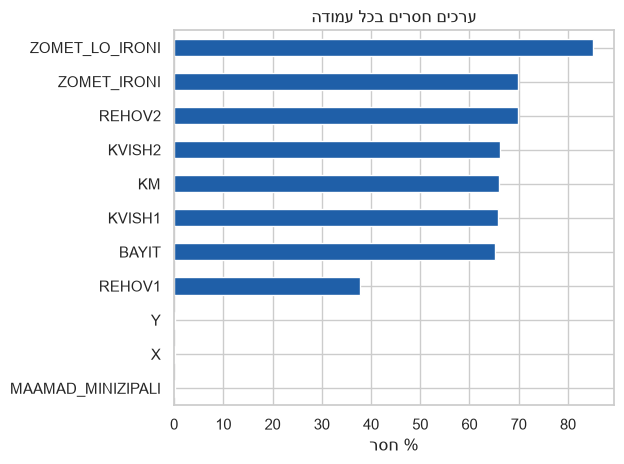

In [5]:
### CODE BY CLAUDE ###
missing = df.isna().mean().mul(100)
missing = missing[missing > 0].sort_values()
ax = missing.plot.barh(color="#1f5fa8")
ax.set_xlabel("% חסר"); ax.set_title("ערכים חסרים בכל עמודה")
plt.tight_layout(); plt.savefig(FIGURES / "02_missing_values.png", dpi=150); plt.show()
####

                     REHOV1  ZOMET_IRONI  KVISH1     KM  ZOMET_LO_IRONI
עירונית בצומת           0.0          1.0   100.0  100.0           100.0
עירונית לא בצומת        9.0        100.0   100.0  100.0           100.0
לא-עירונית בצומת      100.0        100.0     0.0    0.0             0.0
לא-עירונית לא בצומת   100.0        100.0     1.0    3.0           100.0


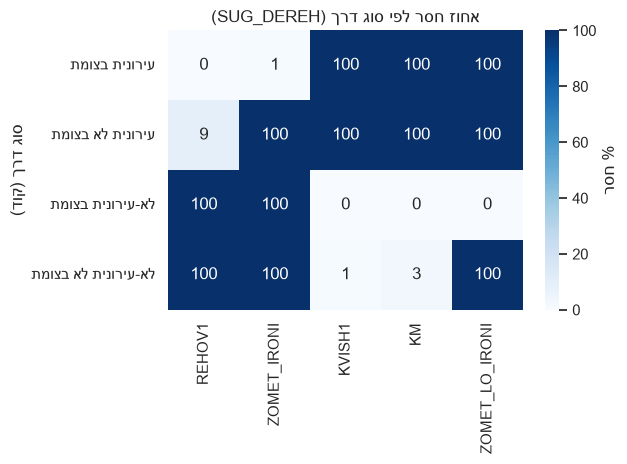

In [6]:
### CODE BY CLAUDE ###
# SUG_DEREH: ‏1–2 = דרך עירונית, 3–4 = דרך בין־עירונית (לאמת במילון)
cols = ["REHOV1", "ZOMET_IRONI", "KVISH1", "KM", "ZOMET_LO_IRONI"]
by_road = df.groupby("SUG_DEREH")[cols].apply(lambda g: g.isna().mean().mul(100).round(0))
by_road.index = [label("SUG_DEREH", c) for c in by_road.index]   # שמות מהמילון במקום קודים
print(by_road)
sns.heatmap(by_road, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% חסר"})
plt.title("אחוז חסר לפי סוג דרך (SUG_DEREH)")
plt.ylabel("סוג דרך (קוד)")
plt.tight_layout(); plt.savefig(FIGURES / "03_missing_by_road_type.png", dpi=150); plt.show()
####

<div dir="rtl">

**מסקנה:** החוסר **מבני**, לא טעות: בתאונה בעיר (SUG_DEREH 1–2) אין מספר כביש וק"מ, ובתאונה בין־עירונית (3–4) אין רחוב.
לכן לא "משלימים" אותם בממוצע. במקום זה יוצרים דגלים: `HAS_STREET`, `HAS_ROAD_NUMBER`, `AT_JUNCTION_ID`.

</div>

<div dir="rtl">

## 4. חומרה מול הפיצ'רים
בכל גרף: **אחוז** התאונות הקטלניות והקשות בכל קטגוריה. אחוז ולא ספירה, כי הקטגוריות בגדלים שונים מאוד.

</div>

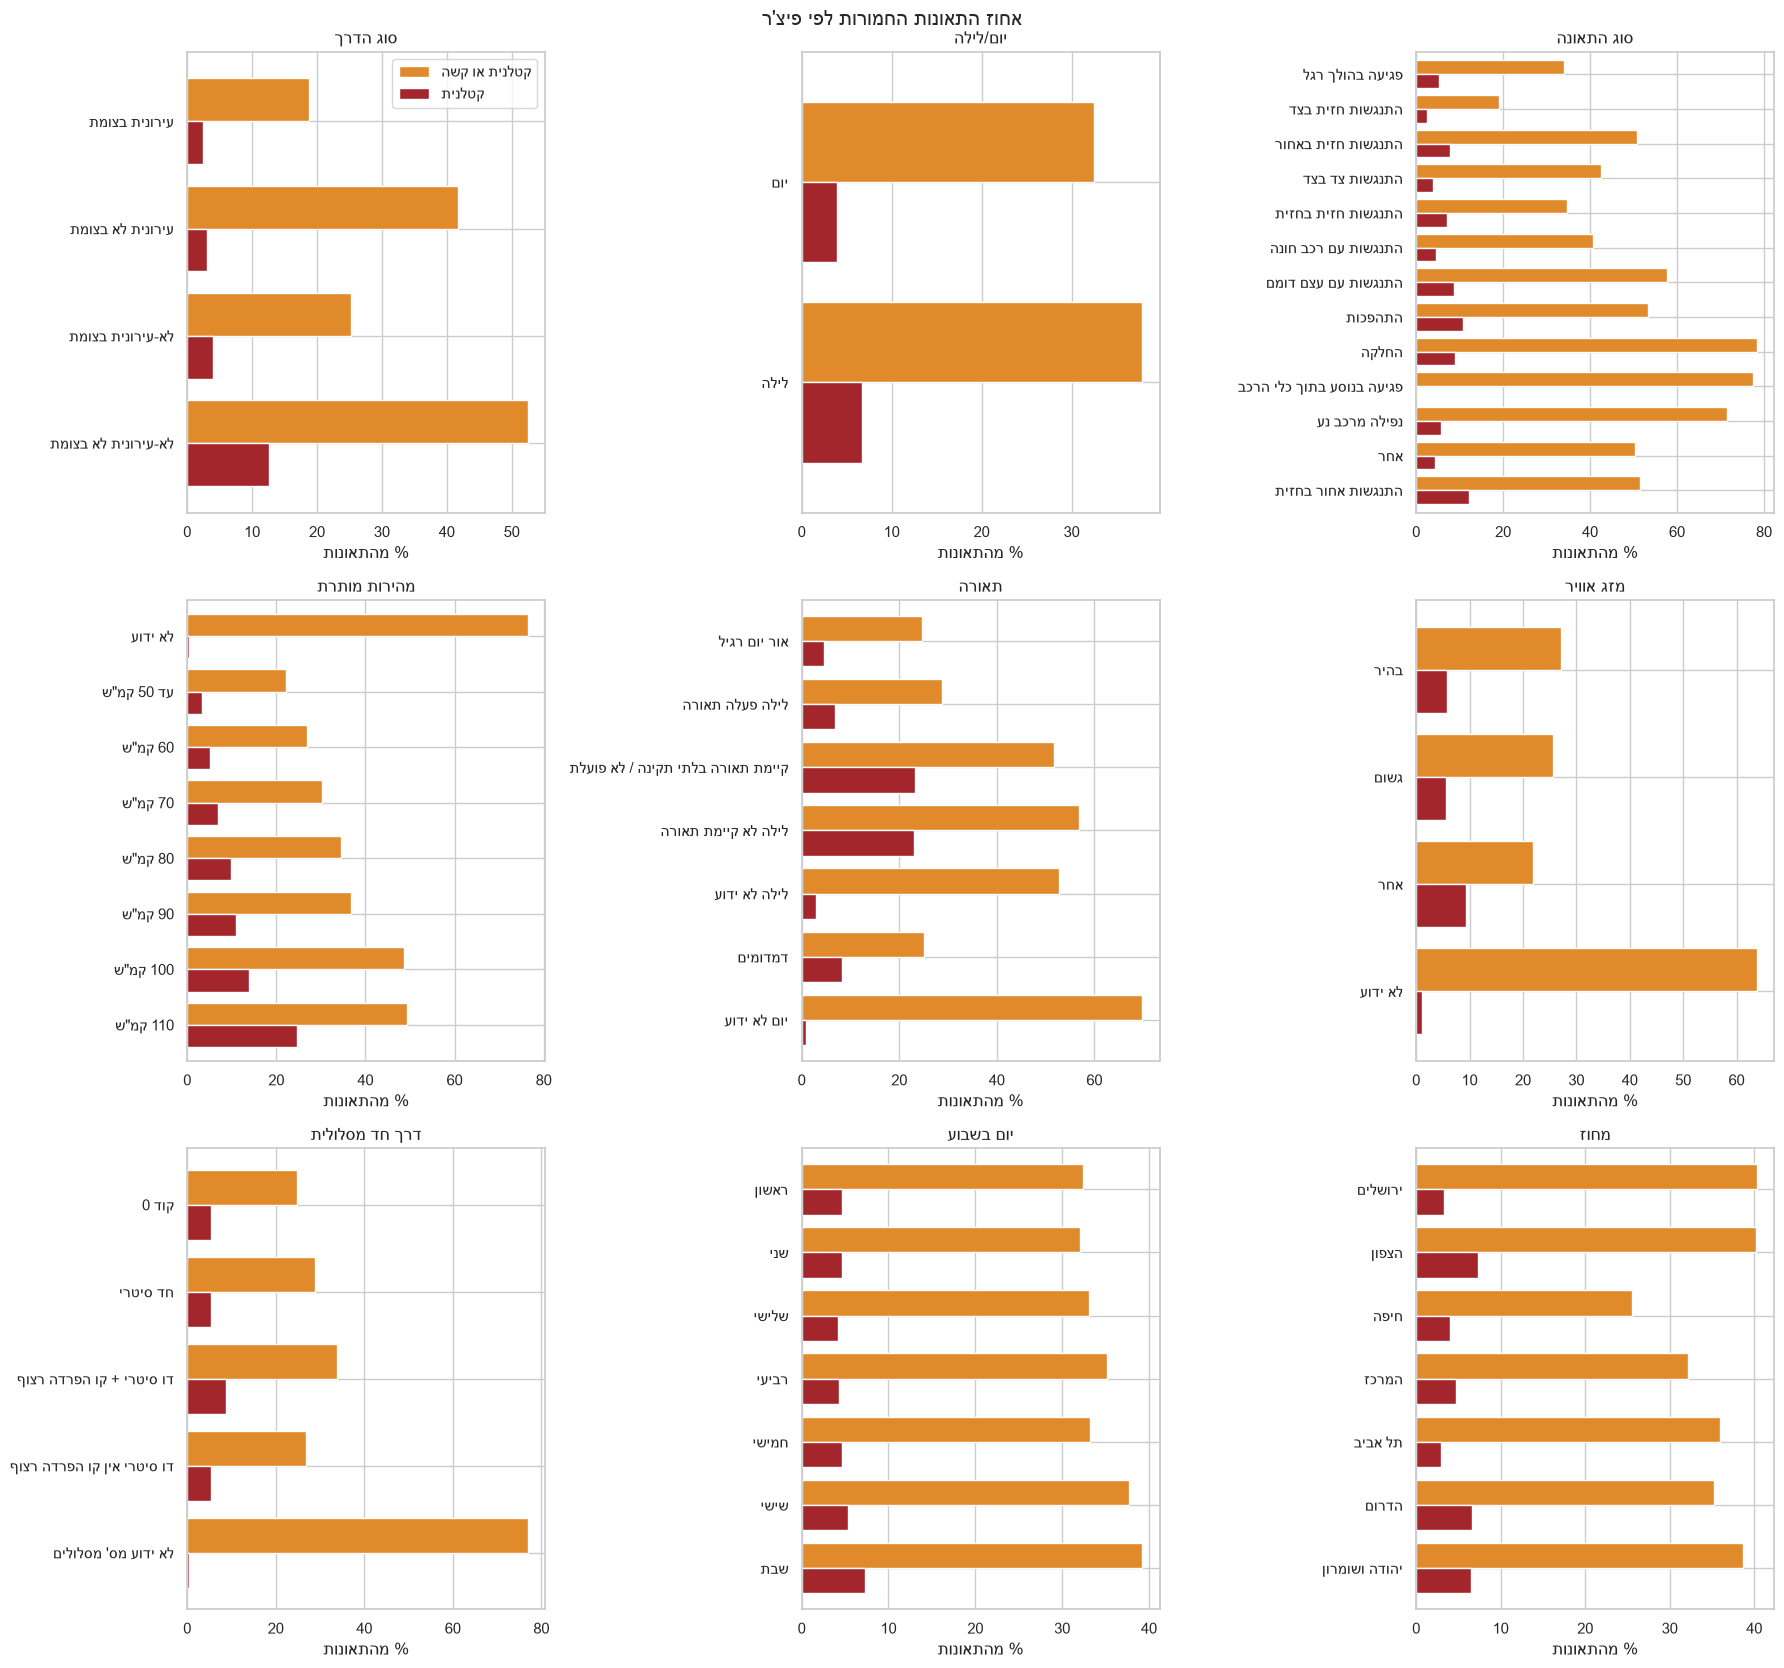

In [7]:
### CODE BY CLAUDE ###
dfe = add_features(df)
dfe["fatal"] = (dfe[TARGET] == 1).astype(int)
dfe["fatal_or_serious"] = (dfe[TARGET] <= 2).astype(int)

def severity_by(col, ax, min_count=30):
    g = dfe.groupby(col).agg(n=("fatal", "size"), fatal=("fatal", "mean"), severe=("fatal_or_serious", "mean"))
    g = g[g["n"] >= min_count]          # בקטגוריה קטנה מאוד האחוזים "רועשים"
    g.index = [label(col, c) for c in g.index]     # שמות מהמילון במקום קודים
    (g[["severe", "fatal"]] * 100).plot.barh(ax=ax, color=["#e08a2c", "#a3262c"], width=0.8, legend=False)
    ax.invert_yaxis()
    ax.set_title(COLUMN_NAMES.get(col, col)); ax.set_xlabel("% מהתאונות"); ax.set_ylabel("")

features = ["SUG_DEREH", "YOM_LAYLA", "SUG_TEUNA", "MEHIRUT_MUTERET", "TEURA",
            "MEZEG_AVIR", "HAD_MASLUL", "YOM_BASHAVUA", "MAHOZ"]
fig, axes = plt.subplots(3, 3, figsize=(18, 17))
for col, ax in zip(features, axes.ravel()):
    severity_by(col, ax)
axes[0, 0].legend(["קטלנית או קשה", "קטלנית"])
fig.suptitle("אחוז התאונות החמורות לפי פיצ'ר")
plt.tight_layout(); plt.savefig(FIGURES / "04_severity_by_feature.png", dpi=150); plt.show()
####

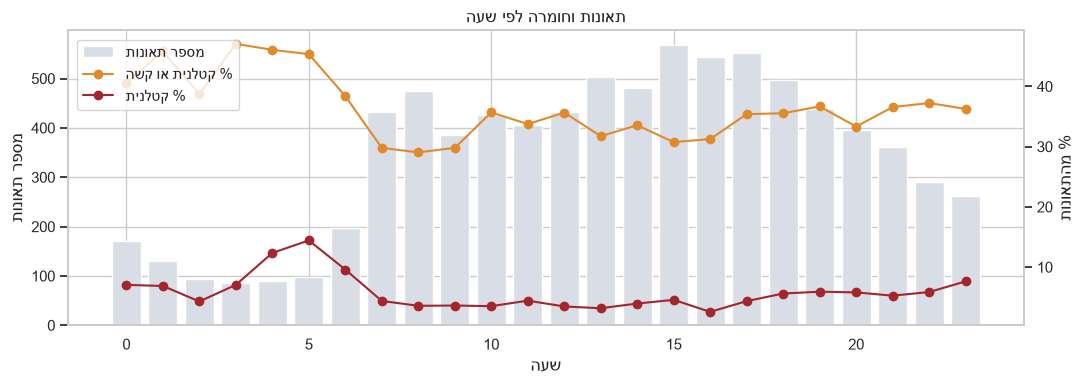

In [8]:
### CODE BY CLAUDE ###
# שעה ביממה (SHAA קובץ לשעות; לאמת את הקידוד במילון)
g = dfe.groupby("HOUR").agg(n=("fatal", "size"), fatal=("fatal", "mean"), severe=("fatal_or_serious", "mean"))
fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(g.index, g["n"], color="#d9dee6", label="מספר תאונות")
ax1.set_xlabel("שעה"); ax1.set_ylabel("מספר תאונות")
ax2 = ax1.twinx()
ax2.plot(g.index, g["severe"] * 100, color="#e08a2c", marker="o", label="% קטלנית או קשה")
ax2.plot(g.index, g["fatal"] * 100, color="#a3262c", marker="o", label="% קטלנית")
ax2.set_ylabel("% מהתאונות"); ax2.grid(False)
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.9))
plt.title("תאונות וחומרה לפי שעה")
plt.tight_layout(); plt.savefig(FIGURES / "05_severity_by_hour.png", dpi=150); plt.show()
####

<div dir="rtl">

**מה לחפש בגרפים (לפגישה):**
- האם תאונות בדרך לא־עירונית חמורות יותר מעירוניות?
- האם בלילה אחוז הקטלניות גבוה יותר, למרות שיש פחות תאונות?
- אילו סוגי תאונה הכי קטלניים? (למשל פגיעה בהולך רגל, התנגשות חזית בחזית, התהפכות)
- האם מהירות מותרת גבוהה יותר = חומרה גבוהה יותר?
- השמות בגרפים לקוחים ממילון הקודים של הלמ"ס (`data/raw/codes_dictionary_subset.csv`). קוד שאין לו שם במילון מופיע כ"קוד N".

</div>

<div dir="rtl">

## 5. מיקום: מפת התאונות

</div>

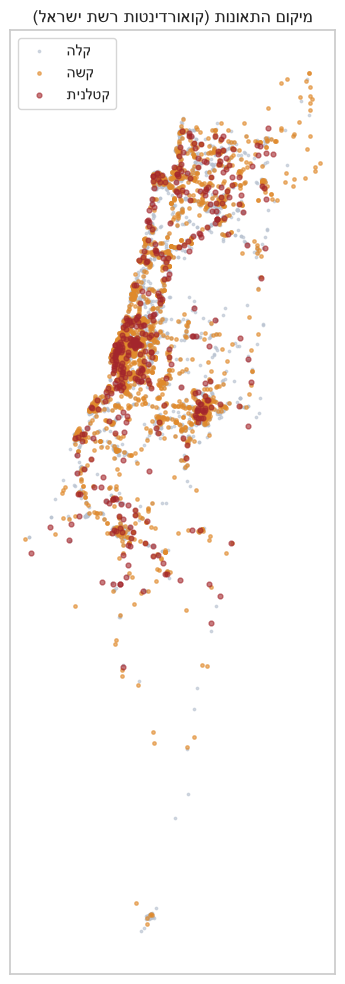

In [9]:
### CODE BY CLAUDE ###
fig, ax = plt.subplots(figsize=(6, 10))
for code_, color, size in [(3, "#b8c2d0", 3), (2, "#e08a2c", 6), (1, "#a3262c", 12)]:
    part = dfe[dfe[TARGET] == code_]
    ax.scatter(part["X"], part["Y"], s=size, c=color, label=SEVERITY_NAMES[code_], alpha=0.6)
ax.set_aspect("equal"); ax.legend(); ax.set_title("מיקום התאונות (קואורדינטות רשת ישראל)")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(FIGURES / "06_map.png", dpi=150); plt.show()
####

<div dir="rtl">

## 6. בדיקת Data Leakage (שיעור 1): ממצא חשוב
אין בקובץ עמודות של מספר נפגעים. אבל בגרף של סעיף 4 יש משהו חשוד: דווקא הקוד של **"לא ידוע"** בשדות תנאי הדרך
(MEHIRUT_MUTERET = 0, MEZEG_AVIR = 9, HAD_MASLUL = 9) מגיע ל־60%–77% תאונות חמורות, הרבה יותר מכל ערך אמיתי.
בודקים את ערכי "לא ידוע" לפי חומרה:

</div>

In [10]:
### CODE BY CLAUDE ###
unknown = pd.DataFrame({
    "MEHIRUT_MUTERET = 0": df["MEHIRUT_MUTERET"] == 0,
    "PNE_KVISH = 9": df["PNE_KVISH"] == 9,
    "MEZEG_AVIR = 9": df["MEZEG_AVIR"] == 9,
    "TKINUT = 0": df["TKINUT"] == 0,
    "ROHAV = 0": df["ROHAV"] == 0,
})
# אחוז "לא ידוע" בכל עמודה, לפי חומרת התאונה
(unknown.groupby(df[TARGET].map(SEVERITY_NAMES)).mean() * 100).round(0).reindex(SEV_ORDER)
####

,MEHIRUT_MUTERET = 0,PNE_KVISH = 9,MEZEG_AVIR = 9,TKINUT = 0,ROHAV = 0
HUMRAT_TEUNA,,,,,
קטלנית,1.0,1.0,4.0,5.0,4.0
קשה,39.0,39.0,42.0,41.0,42.0
קלה,5.0,7.0,11.0,9.0,12.0


In [11]:
### CODE BY CLAUDE ###
from src.data import details_missing
m = details_missing(df)
print(f"תאונות שבהן כל פרטי הדרך לא ידועים: {m.sum()} ({m.mean():.0%})")
print(pd.crosstab(m.map({True: "חסרים פרטים", False: "יש פרטים"}),
                  df[TARGET].map(SEVERITY_NAMES), normalize="index").mul(100).round(1)[SEV_ORDER])
####

תאונות שבהן כל פרטי הדרך לא ידועים: 1235 (15%)
HUMRAT_TEUNA  קטלנית   קשה   קלה
row_0                           
חסרים פרטים      0.3  76.8  22.8
יש פרטים         5.7  21.2  73.1


<div dir="rtl">

**הממצא:** ב־1,235 תאונות (15%) **כל** שדות תנאי הדרך ריקים יחד, ו־77% מהן "קשות", לעומת 21% בשאר הדאטה.
כנראה אלה תאונות שדווחו בדרך אחרת (בלי תיק חקירה מלא). זה **ארטיפקט של הדיווח**, לא תנאי בדרך:
מודל היה לומד "אם חסרים פרטים, אז קשה", וזה לא עוזר לחזות חומרה של תאונה אמיתית.

**ההחלטה (לדיון בפגישה):** בניסוי הראשי מוציאים את השורות האלה (`get_xy(..., drop_missing_details=True)`) ונשארות 7,080 תאונות.
בניסוי נפרד ב־`02_classification` מראים כמה הארטיפקט "מנפח" את התוצאות כשמשאירים אותן.
⚠️ לאמת במילון / במסמך המתודולוגיה של הלמ"ס מאיפה מגיעות התאונות האלה.

</div>


<div dir="rtl">

## 7. איכות הנתונים (שיעור 3)
בשיעור 3: לפני כל מודל בודקים כפילויות, ערכים חסרים, ועמודות שחוזרות על אותו מידע.

</div>

In [12]:
### CODE BY CLAUDE ###
dups = df.drop(columns=["pk_teuna_fikt"]).duplicated().sum()
print("שורות כפולות (בלי עמודת המזהה):", dups)

xy_missing = df[["X", "Y"]].isna().any(axis=1)
print("תאונות בלי קואורדינטות:", xy_missing.sum())
print(df.loc[xy_missing, "SUG_DEREH"].map(lambda c: label("SUG_DEREH", c)).value_counts())
####

שורות כפולות (בלי עמודת המזהה): 0
תאונות בלי קואורדינטות: 22
SUG_DEREH
לא-עירונית לא בצומת    21
עירונית לא בצומת        1
Name: count, dtype: int64


<div dir="rtl">

**ההחלטות:**
- **כפילויות:** אין. הבדיקה נשארת בקוד (`get_xy`), למקרה שהדאטה יתעדכן.
- **חסרים מבניים** (רחוב, כביש, צומת): לא משלימים, כי לחוסר יש סיבה. במקומם יש דגלים (סעיף 3).
- **חסרים לא מבניים** (‏X ו־Y, כ־20 תאונות): **משלימים בחציון** בתוך ה־Pipeline (`SimpleImputer`), במקום לזרוק את השורות.
  חציון ולא ממוצע, כי הוא לא מושפע מערכים קיצוניים. וה־fit רק על ה־train, כדי שלא יהיה Data Leakage.
- **נרמול ו־PCA:** בודקים ב־`02_classification`, ניסוי 5.

</div>

<div dir="rtl">

## סיכום ה־EDA
1. 8,315 תאונות ו־45 עמודות. אחרי הניקוי: 28 קטגוריות, 2 מספריות (X, Y), ו־3 דגלים: יותר מ־15 פיצ'רים משמעותיים.
2. הדאטה לא מאוזן: 4.9% קטלניות (5.7% אחרי הוצאת השורות בלי פרטים).
3. החסרים בעמודות המיקום מבניים, תלויים בסוג הדרך.
4. 15% מהתאונות בלי פרטי דרך בכלל, ורובן "קשות": ארטיפקט שמוציאים מהניסוי הראשי.
5. המשך: `02_classification.ipynb`.

</div>